# MediSafe — Model 2: Alternative Medicine Recommendation

**Proposal objective 3 / AI Model 2:** *"A recommendation and ranking model that identifies clinically eligible
medicine products and compares their prices to help users explore affordable options."*

| Step | Rule | Why |
|---|---|---|
| 1. Eligibility (hard filter) | same **generic** (active ingredients), **strength**, **dosage form** and **type** | a cheaper product is only an alternative if it is the same medicine |
| 2. Ranking | lowest **price per unit** (tablet/capsule, ml, gm or dose) first | packages differ in size (60 ml vs 100 ml), so listed prices are not comparable |
| 3. Output | ranked list + price difference + disclaimer | decision support only; a doctor/pharmacist decides |

This is a **content-based** recommender: there are no user ratings or "substitution" labels in the data, so it is
evaluated with coverage, correctness checks, hand-made test cases and a savings analysis — not with accuracy.

The notebook reuses the project code: `train.py` (builds the eligibility index), `predict.py` (looks it up) and
`price_units.py` (per-unit price, also used by the backend).

**Run:** `cd model2 && pip install -r requirements.txt jupyter`, then open this notebook (runs in < 1 minute).

In [1]:
import json, os, re, tempfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import train, predict
from price_units import normalized_price

pd.set_option("display.max_colwidth", 60)

## 1. Dataset: MedEx medicine catalog (Bangladesh)

In [2]:
med = pd.read_csv("medicine.csv", dtype=str).fillna("")
print(f"{len(med):,} products, {med['generic'].nunique():,} generics, {med['manufacturer'].nunique():,} manufacturers")
med[["brand name", "generic", "strength", "dosage form", "type", "manufacturer", "package container"]].head(6)

21,714 products, 1,662 generics, 232 manufacturers


,brand name,generic,strength,dosage form,type,manufacturer,package container
0,A-Cold,Bromhexine Hydrochloride,4 mg/5 ml,Syrup,allopathic,ACME Laboratories Ltd.,100 ml bottle: ৳ 40.12
1,A-Cof,Dextromethorphan + Pseudoephedrine + Triprolidine,(10 mg+30 mg+1.25 mg)/5 ml,Syrup,allopathic,ACME Laboratories Ltd.,100 ml bottle: ৳ 100.00
2,A-Clox,Cloxacillin Sodium,500 mg/vial,Injection,allopathic,ACME Laboratories Ltd.,"500 mg vial: ৳ 28.43,(5's pack: ৳ 142.15),"
3,A-Clox,Cloxacillin Sodium,250 mg/vial,Injection,allopathic,ACME Laboratories Ltd.,"250 mg vial: ৳ 20.00,(5's pack: ৳ 100.00),"
4,A-Clox,Cloxacillin Sodium,125 mg/5 ml,Powder for Suspension,allopathic,ACME Laboratories Ltd.,100 ml bottle: ৳ 45.00
5,A-Clox,Cloxacillin Sodium,500 mg,Capsule,allopathic,ACME Laboratories Ltd.,"Unit Price: ৳ 5.98,(100's pack: ৳ 598.00),"


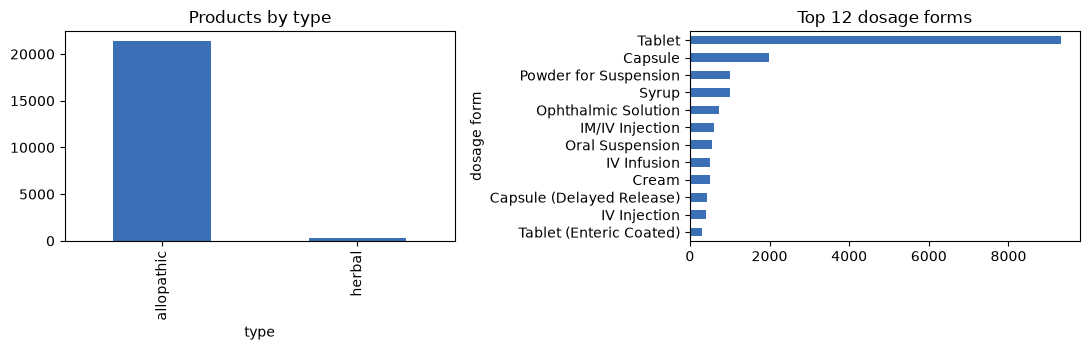

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
med["type"].value_counts().plot.bar(ax=axes[0], color="#3b6fb6", title="Products by type")
med["dosage form"].value_counts().head(12).plot.barh(ax=axes[1], color="#3b6fb6", title="Top 12 dosage forms")
axes[1].invert_yaxis(); plt.tight_layout(); plt.show()

## 2. Price data and why per-unit prices are needed

`package container` holds the price text. Several formats exist; a listed price alone mixes "per tablet" with
"per 100 ml bottle".

In [4]:
fmt = med["package container"].map(lambda p: re.sub(r"[\d.,]+", "N", p.split(":")[0])[:30] if p else "(empty)")
display(fmt.value_counts().head(10).to_frame("products"))
units = med["package container"].map(normalized_price)
med["unit_price"] = units.map(lambda t: t[0]); med["unit"] = units.map(lambda t: t[1])
med["listed_price"] = med["package container"].map(train.extract_unit_price)
print(f"listed price found: {med['listed_price'].notna().mean():.1%}   per-unit price found: {med['unit_price'].notna().mean():.1%}")
med["unit"].value_counts(dropna=False).to_frame("products")

,products
package container,
Unit Price,13501
N ml bottle,3350
N ml drop,978
N gm tube,945
N mg vial,745
N ml ampoule,628
N gm vial,348
N ml vial,228
N ml pre-filled syringe,102


listed price found: 99.6%   per-unit price found: 99.1%


,products
unit,
unit,13501
ml,5484
gm,1409
mg,815
NaN,199
dose,163
tablet,78
IU,65


In [5]:
for p in ["Unit Price: ৳ 1.20,(20's pack: ৳ 24.00)", "100 ml bottle: ৳ 40.12", "60 ml bottle: ৳ 30.00",
          "15 gm tube: ৳ 120.00", "200 metered doses: ৳ 350.00", "Price Unavailable"]:
    print(f"{p:42s} -> {normalized_price(p)}")

Unit Price: ৳ 1.20,(20's pack: ৳ 24.00)    -> (1.2, 'unit')
100 ml bottle: ৳ 40.12                     -> (0.4012, 'ml')
60 ml bottle: ৳ 30.00                      -> (0.5, 'ml')
15 gm tube: ৳ 120.00                       -> (8.0, 'gm')
200 metered doses: ৳ 350.00                -> (1.75, 'dose')
Price Unavailable                          -> (None, None)


## 3. Build the eligibility index (`train.py`)

Products are grouped by the normalized key **(generic, strength, dosage form, type)**. Only groups with at least
two priced products can offer an alternative. (The index is written to a temporary file here; `python train.py`
writes the deployed `models/alternative_recommendation.json`.)

In [6]:
tmp = os.path.join(tempfile.mkdtemp(), "index.json")
model = train.build_recommendation_model("medicine.csv", tmp)
s = model["statistics"]
pd.Series({"medicine rows": s["medicine_rows"], "rows with all match fields": s["rows_with_matching_fields"],
           "rows with a price": s["rows_with_valid_price"], "groups with alternatives": s["eligible_groups_with_alternatives"],
           "products in those groups": s["products_in_eligible_groups"]}).to_frame("count")

,count
medicine rows,21714
rows with all match fields,20863
rows with a price,20785
groups with alternatives,1930
products in those groups,19759


coverage: 91.0% of all products have >= 1 eligible alternative
group size: median 5, max 123


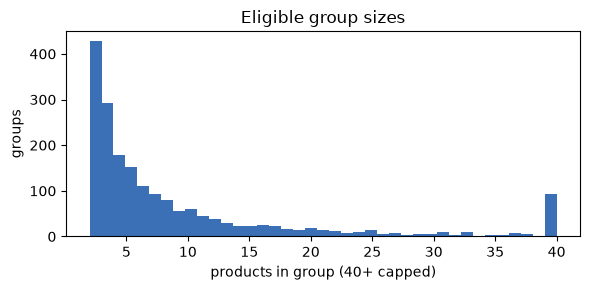

In [7]:
sizes = pd.Series([len(v) for v in model["groups"].values()])
print(f"coverage: {s['products_in_eligible_groups'] / s['medicine_rows']:.1%} of all products have >= 1 eligible alternative")
print(f"group size: median {sizes.median():.0f}, max {sizes.max()}")
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(sizes.clip(upper=40), bins=39, color="#3b6fb6")
ax.set_xlabel("products in group (40+ capped)"); ax.set_ylabel("groups"); ax.set_title("Eligible group sizes")
plt.tight_layout(); plt.show()

## 4. Correctness check: eligibility is never violated

Every product inside a group must share generic, strength, dosage form and type (after normalization).
This is the hard safety constraint (requirement AIR-04), so it is checked over the whole index.

In [8]:
violations = 0
for key, prods in model["groups"].items():
    k = json.loads(key)
    for p in prods:
        if [train.normalize(p["generic"]), train.normalize(p["strength"]),
            train.normalize(p["dosage_form"]), train.normalize(p["type"])] != k:
            violations += 1
print(f"checked {sum(len(v) for v in model['groups'].values()):,} products in {len(model['groups']):,} groups -> violations: {violations}")
assert violations == 0

checked 19,759 products in 1,930 groups -> violations: 0


## 5. Hand-made test cases

Known correct behaviour, written before looking at the output:

1. Paracetamol 500 mg **tablet** → only paracetamol 500 mg tablets (no syrup, no 665 mg, no combinations).
2. Paracetamol 120 mg/5 ml **syrup** → only syrups of that strength.
3. A combination product → only the same combination at the same strengths.
4. Ranking is ascending by price per unit.

In [9]:
def alts(generic, strength, form, kind="allopathic", n=500):
    return predict.find_comparisons_from_model(model, generic, strength, form, kind, n)

r1 = alts("Paracetamol", "500 mg", "Tablet")
assert r1 and all(p["generic"] == "Paracetamol" and p["strength"] == "500 mg" and p["dosage_form"] == "Tablet" for p in r1)
print(f"case 1: {len(r1)} eligible paracetamol 500 mg tablets — all same generic/strength/form ✔")

r2 = alts("Paracetamol", "120 mg/5 ml", "Syrup")
assert r2 and all(p["dosage_form"] == "Syrup" and p["strength"] == "120 mg/5 ml" for p in r2)
print(f"case 2: {len(r2)} eligible paracetamol 120 mg/5 ml syrups ✔")

combo = med[med["generic"].str.contains(r"\+") & (med["type"] == "allopathic")].groupby(
    ["generic", "strength", "dosage form"]).size().sort_values().index[-1]
r3 = alts(*combo)
assert r3 and all(p["generic"] == combo[0] and p["strength"] == combo[1] for p in r3)
print(f"case 3: {combo} -> {len(r3)} products, all the same combination ✔")

def ranked(prods):
    # backend ranking: products with a known unit price first, lowest price per unit first
    out = []
    for p in prods:
        up, u = normalized_price(p["package_container"]); out.append({**p, "unit_price": up, "unit": u})
    return sorted(out, key=lambda p: (p["unit_price"] is None, p["unit_price"] or 0))
rk = ranked(r1); prices = [p["unit_price"] for p in rk if p["unit_price"] is not None]
assert prices == sorted(prices)
print("case 4: ranking ascending by price per unit ✔")
pd.DataFrame(rk)[["brand_name", "manufacturer", "package_container", "unit_price", "unit"]].head(8)

case 1: 74 eligible paracetamol 500 mg tablets — all same generic/strength/form ✔
case 2: 6 eligible paracetamol 120 mg/5 ml syrups ✔
case 3: ('Paracetamol + Caffeine', '500 mg+65 mg', 'Tablet') -> 105 products, all the same combination ✔
case 4: ranking ascending by price per unit ✔


,brand_name,manufacturer,package_container,unit_price,unit
0,Neopara,Bristol Pharmaceuticals Ltd.,"Unit Price: ৳ 0.50,(100's pack: ৳ 50.00),",0.50,unit
1,Promel,Apollo Pharmaceutical Ltd.,"Unit Price: ৳ 0.53,(100's pack: ৳ 53.00),",0.53,unit
2,Centamol,Central Pharmaceuticals Ltd.,"Unit Price: ৳ 0.55,(200's pack: ৳ 110.00),",0.55,unit
3,Hepa,Hudson Pharmaceuticals Ltd.,"Unit Price: ৳ 0.55,(500's pack: ৳ 275.00),",0.55,unit
4,Prefer,Marksman Pharmaceuticals Ltd.,"Unit Price: ৳ 0.55,(300's pack: ৳ 165.00),",0.55,unit
5,Cetadol,Doctor’s Chemical Works Ltd.,"Unit Price: ৳ 0.60,(200's pack: ৳ 120.00),",0.60,unit
6,Cetam,Pacific Pharmaceuticals Ltd.,"Unit Price: ৳ 0.60,(100's pack: ৳ 60.00),,Unit Price: ৳ ...",0.60,unit
7,Depol,Desh Pharmaceuticals Ltd.,"Unit Price: ৳ 0.60,(400's pack: ৳ 240.00),",0.60,unit


## 6. Listed price vs. price per unit

`train.py` ranks by the first listed price. For bottles, tubes and inhalers of different sizes this can put a
more expensive product first. The backend therefore re-ranks by price per unit and compares two products only
when their unit is the same. How often does it matter?

In [10]:
changed, mixed, worst = 0, 0, (0, None)
for prods in model["groups"].values():
    rk = ranked(prods)
    top = prods[0]                                   # train.py: lowest LISTED price first
    top_up, top_u = normalized_price(top["package_container"])
    same_unit = [p["unit_price"] for p in rk if p["unit"] == top_u and p["unit_price"] is not None]
    if top_up is None or len(same_unit) < 2 or len({p["package_container"].split(":")[0] for p in prods}) < 2:
        continue
    mixed += 1
    gap = (top_up - min(same_unit)) / top_up    # how much more the listed-cheapest costs per unit
    if gap > 1e-9:
        changed += 1
        one_unit = len({p["unit"] for p in rk}) == 1    # clean example: every product has the same unit
        if one_unit and gap > worst[0]: worst = (gap, prods)
print(f"groups with different package sizes: {mixed:,}")
print(f"in {changed:,} of them the listed-cheapest product is NOT the cheapest per unit "
      f"(example below: it costs {worst[0]:.0%} more per unit)")
ex = pd.DataFrame(prods_ := worst[1])[["brand_name", "package_container", "listed_price_bdt"]]
ex["unit_price"] = [normalized_price(p["package_container"])[0] for p in prods_]
ex["unit"] = [normalized_price(p["package_container"])[1] for p in prods_]
ex["rank by listed price"] = range(1, len(ex) + 1)
ex["rank by price per unit"] = ex["unit_price"].rank(method="first").astype(int)
ex.head(8)

groups with different package sizes: 272
in 150 of them the listed-cheapest product is NOT the cheapest per unit (example below: it costs 79% more per unit)


,brand_name,package_container,listed_price_bdt,unit_price,unit,rank by listed price,rank by price per unit
0,Clean gel,"10 ml pen device: ৳ 75.00,50 ml bottle: ৳ 100.00,250 ml ...",75.0,7.5,ml,1,10
1,Germlock,"50 ml bottle: ৳ 80.00,100 ml bottle: ৳ 130.00",80.0,1.6,ml,2,1
2,Care-on,"50 ml bottle: ৳ 100.00,100 ml bottle: ৳ 130.00,200 ml bo...",100.0,2.0,ml,3,4
3,Cleanex,"50 ml bottle: ৳ 100.00,100 ml bottle: ৳ 170.00",100.0,2.0,ml,4,5
4,Germgurd,"50 ml bottle: ৳ 100.00,100 ml bottle: ৳ 170.00",100.0,2.0,ml,5,6
5,Handigel,50 ml bottle: ৳ 100.00,100.0,2.0,ml,6,7
6,Steriz,"50 ml bottle: ৳ 100.00,200 ml bottle: ৳ 220.00",100.0,2.0,ml,7,8
7,Washout Gel,"50 ml bottle: ৳ 100.00,100 ml bottle: ৳ 170.00,200 ml bo...",100.0,2.0,ml,8,9


## 7. Savings analysis

For every product that has at least one comparable alternative (same unit), how much cheaper is the cheapest
eligible alternative? This is what a patient could save by asking their doctor or pharmacist about an
equivalent brand.

products with a comparable alternative: 19,648
a cheaper eligible alternative exists for 80.7% of them
median possible saving: 28.8%  (75th percentile 43.8%)


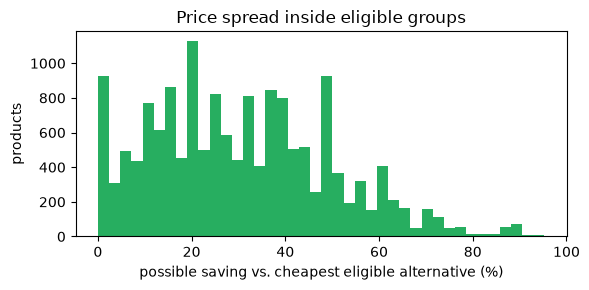

In [11]:
rows = []
for prods in model["groups"].values():
    rk = [p for p in ranked(prods) if p["unit_price"]]
    for p in rk:
        same = [q for q in rk if q["brand_id"] != p["brand_id"] and q["unit"] == p["unit"]]
        if same:
            cheapest = min(q["unit_price"] for q in same)
            rows.append({"brand": p["brand_name"], "unit_price": p["unit_price"], "cheapest_alt": cheapest,
                         "saving_pct": max(0.0, (p["unit_price"] - cheapest) / p["unit_price"] * 100)})
sav = pd.DataFrame(rows)
print(f"products with a comparable alternative: {len(sav):,}")
print(f"a cheaper eligible alternative exists for {(sav.saving_pct > 0).mean():.1%} of them")
print(f"median possible saving: {sav.loc[sav.saving_pct > 0, 'saving_pct'].median():.1f}%  (75th percentile {sav.loc[sav.saving_pct > 0, 'saving_pct'].quantile(.75):.1f}%)")
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(sav.loc[sav.saving_pct > 0, "saving_pct"], bins=40, color="#27ae60")
ax.set_xlabel("possible saving vs. cheapest eligible alternative (%)"); ax.set_ylabel("products")
ax.set_title("Price spread inside eligible groups"); plt.tight_layout(); plt.show()

## 8. Example: what the app shows

In [12]:
q = med[(med["brand name"] == "Napa") & (med["dosage form"] == "Tablet")].iloc[0]
base_up, base_u = normalized_price(q["package container"])
print(f"Selected: {q['brand name']} — {q['generic']} {q['strength']} {q['dosage form']} — ৳ {base_up:.2f} / {base_u}")
out = pd.DataFrame([p for p in ranked(alts(q["generic"], q["strength"], q["dosage form"])) if p["brand_name"] != q["brand name"]])
out["difference"] = (out["unit_price"] - base_up).round(2)
out.insert(0, "rank", range(1, len(out) + 1))
display(out[["rank", "brand_name", "manufacturer", "unit_price", "unit", "difference"]].head(8))
print("Disclaimer shown in the app: price comparison only; consult a doctor or pharmacist before changing any medicine.")

Selected: Napa — Paracetamol 500 mg Tablet — ৳ 1.20 / unit


,rank,brand_name,manufacturer,unit_price,unit,difference
0,1,Neopara,Bristol Pharmaceuticals Ltd.,0.50,unit,-0.70
1,2,Promel,Apollo Pharmaceutical Ltd.,0.53,unit,-0.67
2,3,Centamol,Central Pharmaceuticals Ltd.,0.55,unit,-0.65
3,4,Hepa,Hudson Pharmaceuticals Ltd.,0.55,unit,-0.65
4,5,Prefer,Marksman Pharmaceuticals Ltd.,0.55,unit,-0.65
5,6,Cetadol,Doctor’s Chemical Works Ltd.,0.60,unit,-0.60
6,7,Cetam,Pacific Pharmaceuticals Ltd.,0.60,unit,-0.60
7,8,Depol,Desh Pharmaceuticals Ltd.,0.60,unit,-0.60


Disclaimer shown in the app: price comparison only; consult a doctor or pharmacist before changing any medicine.


## 9. Limitations

* **Exact-match eligibility.** Spelling differences in strength (e.g. "500mg" vs "500 mg") are normalized only
  for spaces and case; other variants are treated as different and may hide valid alternatives.
* **Listed prices only.** Prices come from MedEx listings and may be outdated or differ between pharmacies;
  products without a listed price cannot be ranked.
* **Same unit only.** Products with different units (e.g. per-unit vs per-pack listings) are shown but not
  compared.
* **No clinical judgement.** Excipients, bioequivalence, release mechanism (e.g. SR vs IR may share a form name)
  and patient-specific factors are not modelled. The backend re-checks allergies and conditions, and the app
  always tells the user to consult a professional before switching.